In [ ]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression

In [206]:
df = pd.read_csv('house_data.csv')
df

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,263000018,20140521T000000,360000,3,2.50,1530,1131,3.0,0,0,...,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,6600060120,20150223T000000,400000,4,2.50,2310,5813,2.0,0,0,...,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,1523300141,20140623T000000,402101,2,0.75,1020,1350,2.0,0,0,...,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,291310100,20150116T000000,400000,3,2.50,1600,2388,2.0,0,0,...,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


In [207]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  int64  
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [208]:
df = df.drop(['id', 'date','lat', 'long', 'zipcode'],axis=1)

In [209]:
df.isna().sum()

price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [210]:
df.duplicated().sum()

np.int64(6)

In [211]:
df.drop_duplicates(inplace=True)

In [212]:
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,1340,5650
1,538000,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,1690,7639
2,180000,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,2720,8062
3,604000,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,1360,5000
4,510000,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,1410,1287


In [213]:
for i in df.columns:
    print(df[i].unique(),i)
    print()

[ 221900  538000  180000 ...  610685 1007500  402101] price

[ 3  2  4  5  1  6  7  0  8  9 11 10 33] bedrooms

[1.   2.25 3.   2.   4.5  1.5  2.5  1.75 2.75 3.25 4.   3.5  0.75 4.75
 5.   4.25 3.75 0.   1.25 5.25 6.   0.5  5.5  6.75 5.75 8.   7.5  7.75
 6.25 6.5 ] bathrooms

[1180 2570  770 ... 3087 3118 1425] sqft_living

[ 5650  7242 10000 ...  5813  2388  1076] sqft_lot

[1.  2.  1.5 3.  2.5 3.5] floors

[0 1] waterfront

[0 3 4 2 1] view

[3 5 4 1 2] condition

[ 7  6  8 11  9  5 10 12  4  3 13  1] grade

[1180 2170  770 1050 1680 3890 1715 1060 1890 1860  860 1430 1370 1810
 1980 1600 1200 1250 2330 2270 1070 2450 1710 1750 1400  790 2570 2320
 1190 1510 1090 1280  930 2360  890 2620 2600 3595 1570  920 3160  990
 2290 2165 1640 1000 2130 2830 2250 2420 3250 1850 1590 1260 2519 1540
 1110 1770 2720 2240 3070 2380 2390  880 1040  910 3450 2350 1900 1010
  960 2660 1610  765 3520 1290 1960 1160 1210 1270 1440 2190 2920 1460
 1170 1240 3140 2030 2310  700 1080 2520 2780 1560 1450 17

In [214]:
def valid_yr_renovated(a):
    if a == 0:
        return 0
    else :
        return 1
df['yr_renovated'] = df.yr_renovated.apply(valid_yr_renovated)
df['yr_renovated'].unique()

array([0, 1])

In [215]:
def bath_int(a):
    return a // 1
df['bathrooms'] = df.bathrooms.apply(bath_int)
df['bathrooms'].unique()

array([1., 2., 3., 4., 0., 5., 6., 8., 7.])

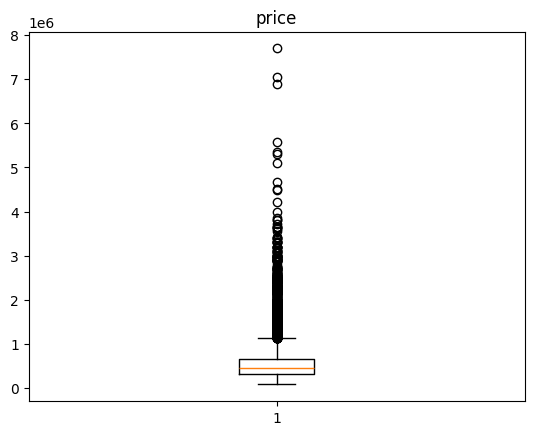

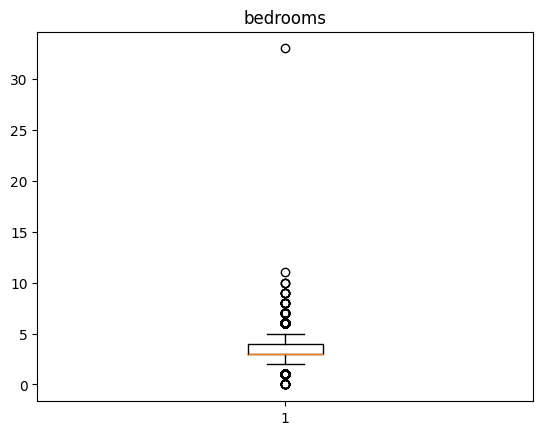

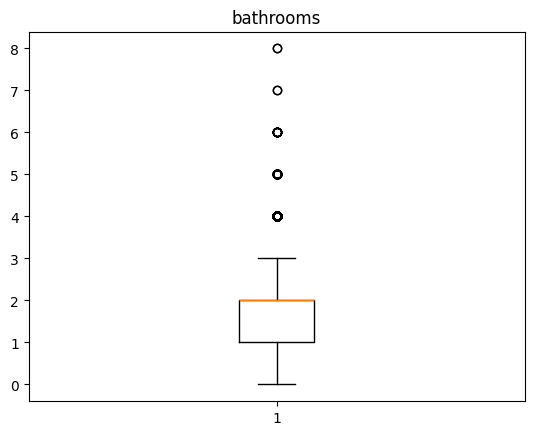

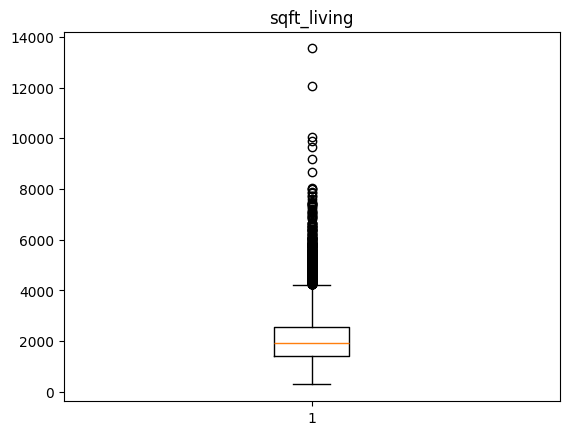

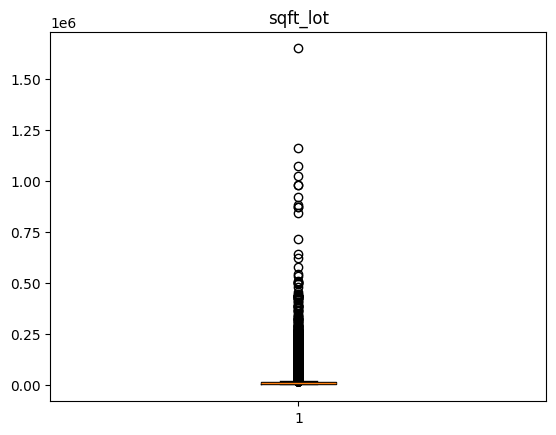

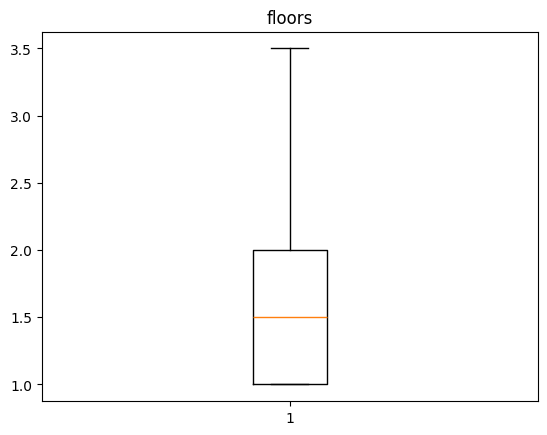

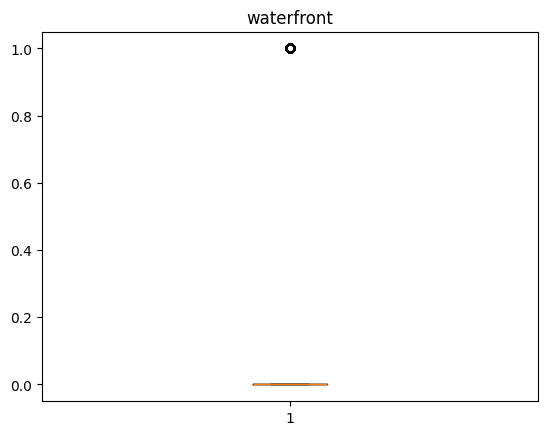

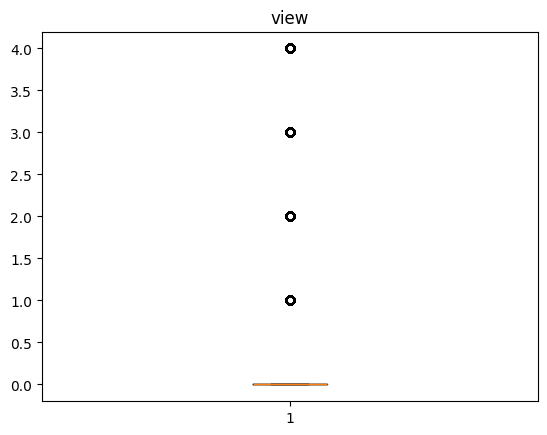

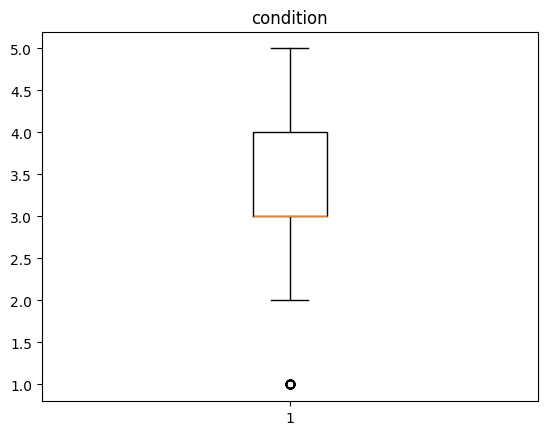

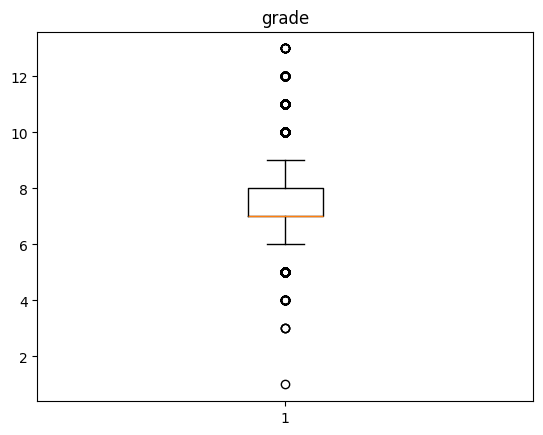

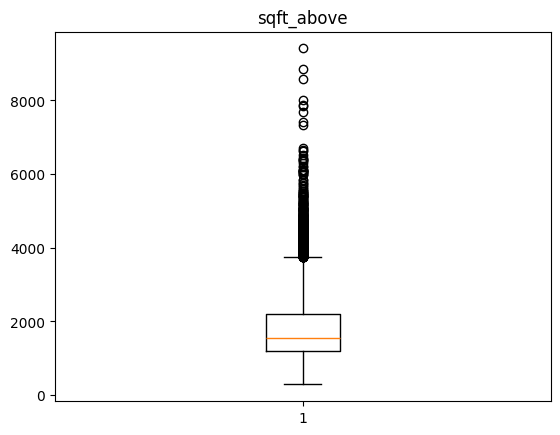

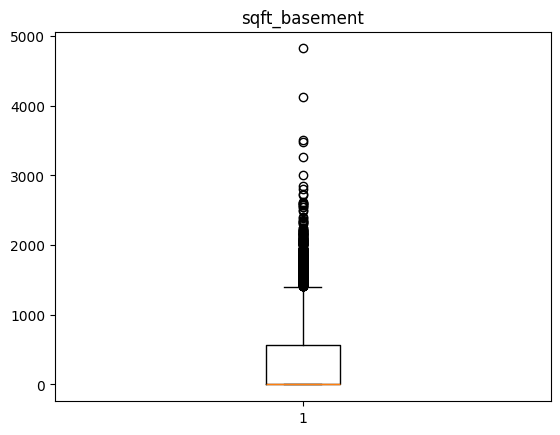

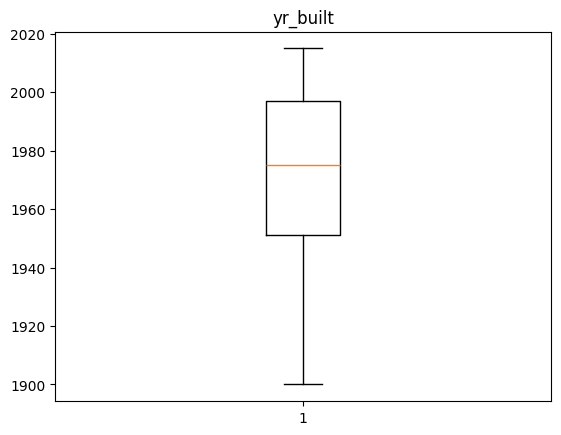

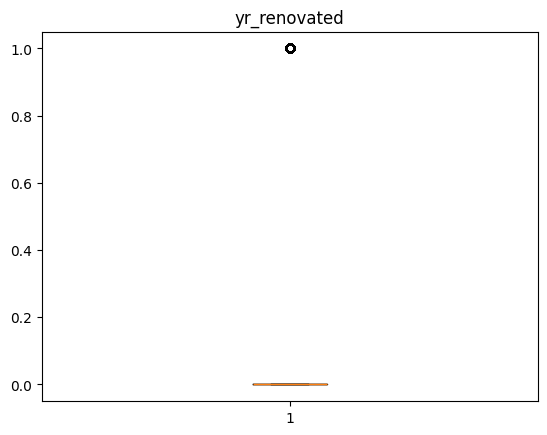

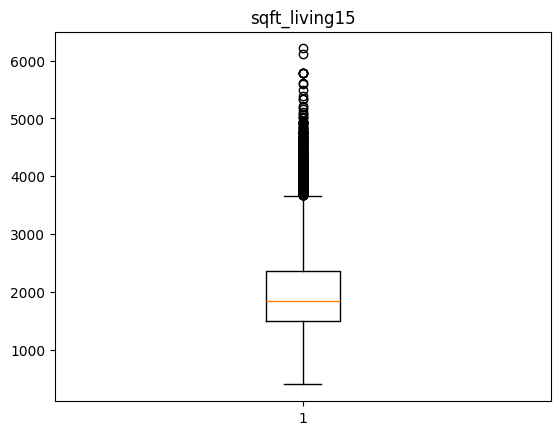

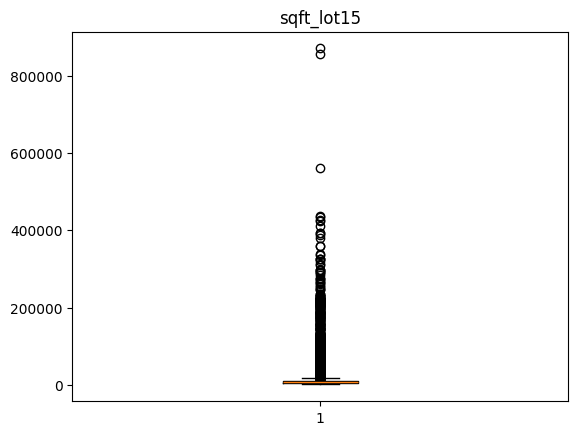

In [216]:
import matplotlib.pyplot as plt
for i in df.columns:
    plt.boxplot(df[i])
    plt.title(i)
    plt.show()

In [217]:
Q1_badroom = df.bedrooms.quantile(.25)
Q3_badroom = df.bedrooms.quantile(.75)
IQR_badroom = Q3_badroom - Q1_badroom

In [218]:
df['bedrooms'].value_counts().sort_index()

bedrooms
0       13
1      199
2     2759
3     9821
4     6881
5     1600
6      272
7       38
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64

In [219]:
LW_badroom = Q1_badroom - 1.5 * IQR_badroom
UW_badroom = Q3_badroom + 1.5 * IQR_badroom
df[(df['bedrooms']<LW_badroom) | (df['bedrooms']>UW_badroom)]


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
154,350000,1,1.0,700,5100,1.0,0,0,3,7,700,0,1942,0,1010,5100
209,464000,6,3.0,2300,3404,2.0,0,0,3,7,1600,700,1920,1,1560,1312
232,315000,6,2.0,2940,7350,1.0,0,0,3,8,1780,1160,1978,0,2120,8236
239,472000,6,2.0,4410,14034,1.0,0,2,4,9,2350,2060,1965,0,2600,13988
264,369900,1,0.0,760,10079,1.0,1,4,5,5,760,0,1936,0,1230,14267
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21375,1174660,6,3.0,4310,7760,2.0,0,0,3,10,3260,1050,2013,0,4620,10217
21443,250000,1,1.0,1180,1688,2.0,0,0,3,8,1070,110,2007,0,1380,2059
21519,420000,1,2.0,1070,675,2.0,0,0,3,8,880,190,2007,0,1220,788
21522,462500,6,3.0,2390,4000,2.0,0,0,3,7,2390,0,2014,0,1680,5000


In [220]:
df = df[(df['bedrooms'] <= 9) & (df['bedrooms'] > 0)]
df

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
0,221900,3,1.0,1180,5650,1.0,0,0,3,7,1180,0,1955,0,1340,5650
1,538000,3,2.0,2570,7242,2.0,0,0,3,7,2170,400,1951,1,1690,7639
2,180000,2,1.0,770,10000,1.0,0,0,3,6,770,0,1933,0,2720,8062
3,604000,4,3.0,1960,5000,1.0,0,0,5,7,1050,910,1965,0,1360,5000
4,510000,3,2.0,1680,8080,1.0,0,0,3,8,1680,0,1987,0,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,360000,3,2.0,1530,1131,3.0,0,0,3,8,1530,0,2009,0,1530,1509
21609,400000,4,2.0,2310,5813,2.0,0,0,3,8,2310,0,2014,0,1830,7200
21610,402101,2,0.0,1020,1350,2.0,0,0,3,7,1020,0,2009,0,1020,2007
21611,400000,3,2.0,1600,2388,2.0,0,0,3,8,1600,0,2004,0,1410,1287


In [221]:
corr = df.corr()

In [222]:
corr

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,sqft_living15,sqft_lot15
price,1.000000,0.317080,0.510670,0.701929,0.089834,0.257105,0.266462,0.397353,0.036089,0.667904,0.605434,0.323654,0.054066,0.126252,0.585295,0.082753
bedrooms,0.317080,1.000000,0.479601,0.594546,0.033878,0.184385,-0.006750,0.082417,0.023576,0.369168,0.494308,0.308760,0.163006,0.017238,0.406894,0.032091
bathrooms,0.510670,0.479601,1.000000,0.698681,0.085998,0.475966,0.058853,0.177749,-0.126866,0.607685,0.641249,0.249914,0.434867,0.059883,0.511335,0.081955
sqft_living,0.701929,0.594546,0.698681,1.000000,0.173414,0.354381,0.103909,0.284615,-0.059325,0.763094,0.876537,0.434887,0.318609,0.054882,0.756564,0.184246
sqft_lot,0.089834,0.033878,0.085998,0.173414,1.000000,-0.004748,0.021617,0.074922,-0.008873,0.114536,0.184075,0.015417,0.052983,0.007854,0.144668,0.718204
floors,0.257105,0.184385,0.475966,0.354381,-0.004748,1.000000,0.023808,0.028935,-0.263936,0.458849,0.524293,-0.245609,0.489477,0.006034,0.280501,-0.010677
waterfront,0.266462,-0.006750,0.058853,0.103909,0.021617,0.023808,1.000000,0.402164,0.016624,0.082887,0.072136,0.080629,-0.026151,0.093414,0.086516,0.030763
view,0.397353,0.082417,0.177749,0.284615,0.074922,0.028935,0.402164,1.000000,0.045974,0.251667,0.167612,0.276926,-0.053574,0.103530,0.280560,0.072870
condition,0.036089,0.023576,-0.126866,-0.059325,-0.008873,-0.263936,0.016624,0.045974,1.000000,-0.146106,-0.158745,0.173899,-0.361329,-0.060418,-0.092894,-0.003201
grade,0.667904,0.369168,0.607685,0.763094,0.114536,0.458849,0.082887,0.251667,-0.146106,1.000000,0.756240,0.168427,0.447563,0.014036,0.713961,0.120678


<Axes: >

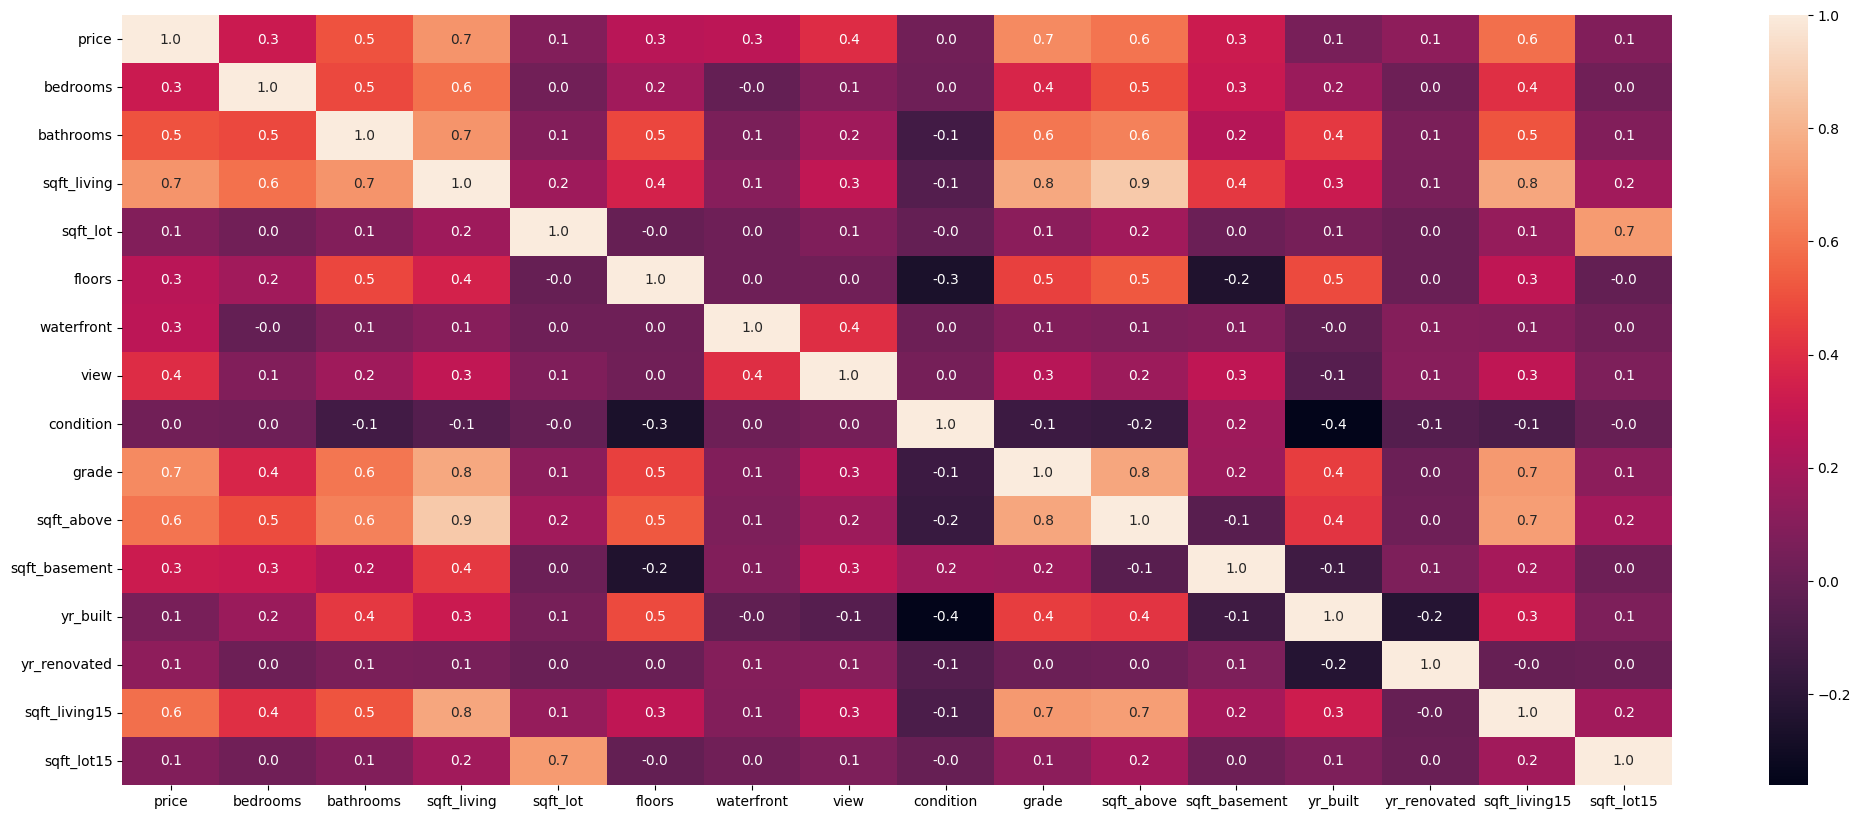

In [223]:
plt.figure(figsize=(25,10))
sns.heatmap(corr,annot=True,fmt='.1f')

In [224]:
sum_price = df.groupby('condition')
sum_price = pd.DataFrame(sum_price['condition'].value_counts()).reset_index()
sum_price

,condition,count
0,1,29
1,2,171
2,3,14014
3,4,5675
4,5,1700


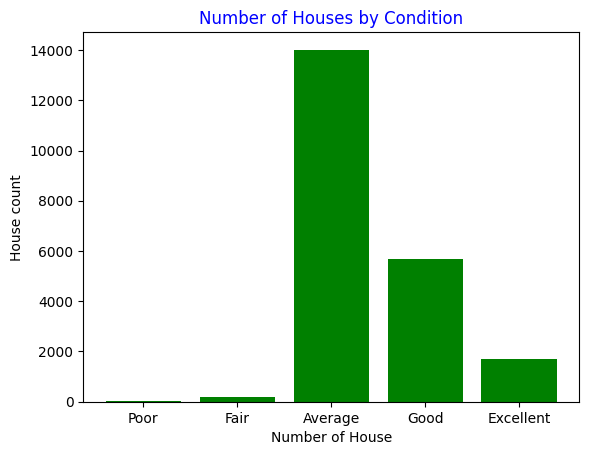

In [225]:
plt.bar(sum_price['condition'],sum_price['count'],color='g')
plt.title('Number of Houses by Condition',color = 'b')
plt.xticks(sum_price['condition'],['Poor','Fair','Average','Good','Excellent'])
plt.xlabel('Number of House')
plt.ylabel('House count')
plt.show()

In [226]:
grade_count = df.groupby(['grade'])
grade_count = pd.DataFrame(grade_count['grade'].value_counts()).reset_index()
grade_count

,grade,count
0,3,3
1,4,27
2,5,242
3,6,2038
4,7,8971
5,8,6062
6,9,2611
7,10,1134
8,11,399
9,12,89


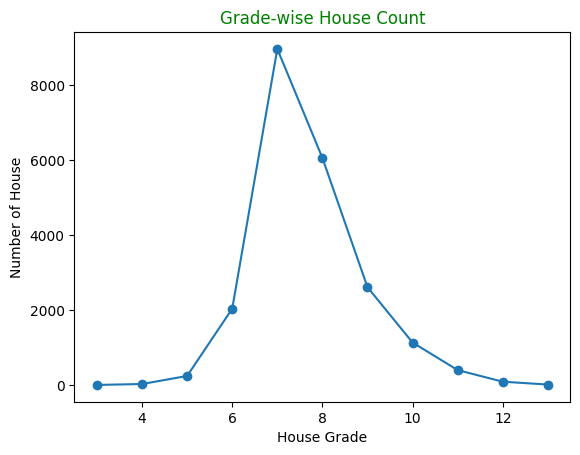

In [227]:
plt.plot(grade_count['grade'],grade_count['count'],marker='o')
plt.title('Grade-wise House Count',color = 'g')
plt.xlabel('House Grade')
plt.ylabel('Number of House')
plt.show()

In [228]:
x = df.drop('price',axis=1)
y = df['price']

In [229]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [230]:
scaler = StandardScaler()
x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

In [231]:
tree = DecisionTreeRegressor( max_depth=20,min_samples_split=3,min_samples_leaf=4,max_features='sqrt',random_state=42)
tree.fit(x_train,y_train)
tree_y_test_pred = tree.predict(x_test)
tree_y_train_pred = tree.predict(x_train)

In [232]:
train_r2_tree = r2_score(y_train,tree_y_train_pred)
test_r2_tree = r2_score(y_test,tree_y_test_pred)
print('train',train_r2_tree,'test',test_r2_tree)

train 0.8311013643056196 test 0.6320327586605933


In [233]:
KNN = KNeighborsRegressor(n_neighbors=5)
KNN.fit(x_train_scaler,y_train)
KNN_test_pred = KNN.predict(x_test_scaler)
KNN_train_pred = KNN.predict(x_train_scaler)

In [234]:
train_r2_KNN = r2_score(y_train,KNN_train_pred)
test_r2_KNN = r2_score(y_test,KNN_test_pred)
print('KNN train',train_r2_KNN,'KNN test :',test_r2_KNN)

KNN train 0.7981058167464785 KNN test : 0.7037495442667806


In [235]:
le = LinearRegression()
le.fit(x_train_scaler,y_train)
le_pred = le.predict(x_test_scaler)

In [236]:
y_train_pred = le.predict(x_train_scaler)
train_r2 = r2_score(y_train, y_train_pred)

y_test_pred = le.predict(x_test_scaler)
test_r2 = r2_score(y_test, y_test_pred)

print("Train R²:", train_r2)
print("Test R² :", test_r2)

Train R²: 0.6539205649718132
Test R² : 0.6681483209417066


In [266]:
from sklearn.ensemble import RandomForestRegressor
random = RandomForestRegressor( n_estimators=800,       
    max_depth=10,              
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1,
)
random.fit(x_train,y_train)
random_train_pred = random.predict(x_train)
random_test_pred = random.predict(x_test)

In [267]:
random_train_r2 = r2_score(y_train,random_train_pred)
random_test_r2 = r2_score(y_test,random_test_pred)
print('random train',random_train_r2,'random test :',random_test_r2)

print("MSE  : ", mean_squared_error(y_test,random_test_pred))
print("MAE  : ", mean_absolute_error(y_test,random_test_pred))

random train 0.8569742949806911 random test : 0.7669898771673944
MSE  :  30994098376.123856
MAE  :  117951.64735099561


In [ ]:
import pickle as p
p.dump(random,open('model.sav','wb'))

In [ ]:
x_train.columns

Index(['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors',
       'waterfront', 'view', 'condition', 'grade', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'sqft_living15',
       'sqft_lot15'],
      dtype='object')